# Proyek Analisis Data: [Input Nama Dataset]
- **Nama:** [Input Nama]
- **Email:** [Input Email]
- **ID Dicoding:** [Input Username]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana perbedaan rata-rata jumlah penyewaan sepeda pada setiap musim selama periode 2011–2012, dan musim mana yang perlu menjadi prioritas dalam perencanaan ketersediaan sepeda?

- **Pertanyaan 2:** Pada jam berapa rata-rata penyewaan sepeda mencapai nilai tertinggi pada hari kerja dan hari libur selama periode 2011–2012, sehingga jadwal ketersediaan sepeda dapat disesuaikan dengan pola permintaan?

## Import Semua Packages/Library yang Digunakan

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Semua library berhasil diimpor.")

Semua library berhasil diimpor.


## Data Wrangling

### Gathering Data

#### Load df ...

In [24]:
# Memuat dataset penyewaan sepeda harian dan per jam
day_df = pd.read_csv("day.csv")
hour_df = pd.read_csv("hour.csv")

# Menampilkan lima data pertama
print("Dataset harian:")
display(day_df.head())

print("Dataset per jam:")
display(hour_df.head())

# Memeriksa ukuran dataset
print("Ukuran dataset harian:", day_df.shape)
print("Ukuran dataset per jam:", hour_df.shape)

Dataset harian:


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


Dataset per jam:


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


Ukuran dataset harian: (731, 16)
Ukuran dataset per jam: (17379, 17)


**Insight:** (Opsional)
- Dataset harian berisi informasi penyewaan sepeda, kondisi cuaca, musim, dan karakteristik hari.
- Dataset per jam menyediakan informasi tambahan mengenai jumlah penyewaan pada setiap jam sehingga dapat digunakan untuk menganalisis pola permintaan berdasarkan waktu.

### Assessing Data

#### Identifying Missing Values, Duplicate Data, and Invalid Values

In [25]:
# Memeriksa informasi umum dataset
print("Informasi dataset harian:")
day_df.info()

print("\nInformasi dataset per jam:")
hour_df.info()

# Memeriksa missing values
print("\nMissing values pada dataset harian:")
display(day_df.isna().sum())

print("\nMissing values pada dataset per jam:")
display(hour_df.isna().sum())

# Memeriksa data duplikat
print("\nJumlah duplikat dataset harian:", day_df.duplicated().sum())
print("Jumlah duplikat dataset per jam:", hour_df.duplicated().sum())

# Memeriksa statistik deskriptif
print("\nStatistik deskriptif dataset harian:")
display(day_df.describe())

print("\nStatistik deskriptif dataset per jam:")
display(hour_df.describe())

# Memeriksa konsistensi jumlah penyewaan
print(
    "Jumlah baris dengan cnt tidak sama dengan casual + registered:",
    (day_df["cnt"] != day_df["casual"] + day_df["registered"]).sum()
)

print(
    "Jumlah baris per jam dengan cnt tidak sama dengan casual + registered:",
    (hour_df["cnt"] != hour_df["casual"] + hour_df["registered"]).sum()
)

# Memeriksa rentang kategori dan nilai penting
print("\nKategori musim:", sorted(day_df["season"].dropna().unique()))
print("Kategori cuaca:", sorted(day_df["weathersit"].dropna().unique()))
print("Rentang jam:", hour_df["hr"].min(), "-", hour_df["hr"].max())
print("Jumlah penyewaan negatif pada dataset harian:",
      (day_df["cnt"] < 0).sum())
print("Jumlah penyewaan negatif pada dataset per jam:",
      (hour_df["cnt"] < 0).sum())

Informasi dataset harian:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

Informasi dataset per jam:
<class 'pandas.core.frame.DataFrame'>
R

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0



Missing values pada dataset per jam:


,0
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0



Jumlah duplikat dataset harian: 0
Jumlah duplikat dataset per jam: 0

Statistik deskriptif dataset harian:


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000



Statistik deskriptif dataset per jam:


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


Jumlah baris dengan cnt tidak sama dengan casual + registered: 0
Jumlah baris per jam dengan cnt tidak sama dengan casual + registered: 0

Kategori musim: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Kategori cuaca: [np.int64(1), np.int64(2), np.int64(3)]
Rentang jam: 0 - 23
Jumlah penyewaan negatif pada dataset harian: 0
Jumlah penyewaan negatif pada dataset per jam: 0


**Steps to Take:**
- Missing values: memeriksa seluruh kolom. Jika ditemukan nilai kosong pada kolom yang digunakan, menentukan penanganan sesuai karakteristik data dan mencatat jumlahnya sebelum pembersihan.
- Duplicate data: memeriksa baris duplikat dan menghapus duplikasi yang benar-benar berulang agar tidak menyebabkan penghitungan penyewaan secara berlebihan.
- Invalid values: memeriksa nilai negatif pada jumlah penyewaan, rentang jam, kategori musim, kategori cuaca, dan konsistensi `cnt = casual + registered`. Nilai yang tidak valid perlu diperiksa sebelum digunakan.
- Outlier: menggunakan statistik deskriptif untuk mengidentifikasi nilai ekstrem. Nilai penyewaan yang tinggi tidak langsung dihapus karena dapat mencerminkan permintaan nyata.

**Insight:** (Opsional)
- Pemeriksaan kualitas data dilakukan sebelum eksplorasi untuk memastikan hasil analisis tidak dipengaruhi oleh duplikasi atau nilai yang tidak valid.
- Hasil pemeriksaan missing values, duplikasi, dan validitas nilai digunakan untuk menentukan tindakan pada tahap cleaning. Kesimpulan mengenai masalah yang benar-benar ditemukan mengikuti output pemeriksaan.

### Cleaning Data

#### Fixing Missing Values, Duplicate Data, and Data Types

In [26]:
# Membuat salinan dataset agar data mentah tetap tersedia
day_clean = day_df.copy()
hour_clean = hour_df.copy()

# Mengubah kolom tanggal menjadi tipe datetime
day_clean["dteday"] = pd.to_datetime(day_clean["dteday"])
hour_clean["dteday"] = pd.to_datetime(hour_clean["dteday"])

# Menghapus baris duplikat
day_clean = day_clean.drop_duplicates().copy()
hour_clean = hour_clean.drop_duplicates().copy()

# Menghapus baris yang memiliki nilai kosong
# pada kolom-kolom yang digunakan dalam analisis
day_clean = day_clean.dropna(
    subset=["dteday", "season", "weathersit", "cnt",
            "casual", "registered"]
).copy()

hour_clean = hour_clean.dropna(
    subset=["dteday", "hr", "workingday", "weathersit",
            "cnt", "casual", "registered"]
).copy()

# Memastikan jumlah penyewaan tidak negatif
day_clean = day_clean[
    (day_clean["cnt"] >= 0) &
    (day_clean["casual"] >= 0) &
    (day_clean["registered"] >= 0)
].copy()

hour_clean = hour_clean[
    (hour_clean["cnt"] >= 0) &
    (hour_clean["casual"] >= 0) &
    (hour_clean["registered"] >= 0) &
    (hour_clean["hr"].between(0, 23))
].copy()

# Memeriksa konsistensi total penyewaan
day_clean = day_clean[
    day_clean["cnt"] ==
    day_clean["casual"] + day_clean["registered"]
].copy()

hour_clean = hour_clean[
    hour_clean["cnt"] ==
    hour_clean["casual"] + hour_clean["registered"]
].copy()

# Memastikan data terurut berdasarkan tanggal dan jam
day_clean = day_clean.sort_values("dteday").reset_index(drop=True)
hour_clean = hour_clean.sort_values(
    ["dteday", "hr"]
).reset_index(drop=True)

# Memeriksa hasil cleaning
print("Ukuran dataset harian sebelum cleaning:", day_df.shape)
print("Ukuran dataset harian setelah cleaning:", day_clean.shape)

print("\nUkuran dataset per jam sebelum cleaning:", hour_df.shape)
print("Ukuran dataset per jam setelah cleaning:", hour_clean.shape)

print("\nMissing values setelah cleaning:")
print("Harian:", day_clean.isna().sum().sum())
print("Per jam:", hour_clean.isna().sum().sum())

print("\nDuplikat setelah cleaning:")
print("Harian:", day_clean.duplicated().sum())
print("Per jam:", hour_clean.duplicated().sum())

Ukuran dataset harian sebelum cleaning: (731, 16)
Ukuran dataset harian setelah cleaning: (731, 16)

Ukuran dataset per jam sebelum cleaning: (17379, 17)
Ukuran dataset per jam setelah cleaning: (17379, 17)

Missing values setelah cleaning:
Harian: 0
Per jam: 0

Duplikat setelah cleaning:
Harian: 0
Per jam: 0


**Insight:** (Opsional)
- Dataset yang telah dibersihkan disimpan dalam `day_clean` dan `hour_clean`, sedangkan dataset awal tetap tersedia untuk perbandingan.
- Nilai tanggal telah dikonversi menjadi datetime, duplikasi dihapus, dan baris yang tidak memenuhi pemeriksaan kualitas data dikeluarkan dari analisis. Jumlah baris yang berubah dapat dilihat dari output sebelum dan sesudah cleaning.

## Exploratory Data Analysis (EDA)

### Explore Seasonal Demand, Hourly Demand, and Weather Conditions

In [27]:
# Periode dataset
print(
    "Periode dataset:",
    day_clean["dteday"].min().date(),
    "hingga",
    day_clean["dteday"].max().date()
)

# Pemetaan kode musim
season_labels = {
    1: "Spring",
    2: "Summer",
    3: "Fall",
    4: "Winter"
}

# Rata-rata dan total penyewaan berdasarkan musim
season_summary = (
    day_clean.groupby("season")
    .agg(
        average_rentals=("cnt", "mean"),
        total_rentals=("cnt", "sum"),
        number_of_days=("cnt", "count")
    )
    .reset_index()
)

season_summary["season_name"] = season_summary["season"].map(
    season_labels
)

season_summary = season_summary.sort_values("season")

print("Ringkasan penyewaan berdasarkan musim:")
display(season_summary)

# Rata-rata penyewaan per jam berdasarkan hari kerja/libur
hour_summary = (
    hour_clean.groupby(["workingday", "hr"])
    .agg(
        average_rentals=("cnt", "mean"),
        total_rentals=("cnt", "sum"),
        observations=("cnt", "count")
    )
    .reset_index()
)

hour_summary["day_type"] = hour_summary["workingday"].map({
    0: "Weekend/Holiday",
    1: "Working Day"
})

print("Rata-rata penyewaan per jam:")
display(hour_summary.head(10))

# Rata-rata penyewaan berdasarkan kondisi cuaca
weather_summary = (
    day_clean.groupby("weathersit")
    .agg(
        average_rentals=("cnt", "mean"),
        total_rentals=("cnt", "sum"),
        number_of_days=("cnt", "count")
    )
    .reset_index()
)

print("Ringkasan berdasarkan kondisi cuaca:")
display(weather_summary)

# Statistik korelasi antara variabel numerik terpilih
correlation = day_clean[
    ["temp", "atemp", "hum", "windspeed", "cnt"]
].corr()

print("Korelasi variabel numerik:")
display(correlation)

Periode dataset: 2011-01-01 hingga 2012-12-31
Ringkasan penyewaan berdasarkan musim:


,season,average_rentals,total_rentals,number_of_days,season_name
0,1,2604.132597,471348,181,Spring
1,2,4992.331522,918589,184,Summer
2,3,5644.303191,1061129,188,Fall
3,4,4728.162921,841613,178,Winter


Rata-rata penyewaan per jam:


,workingday,hr,average_rentals,total_rentals,observations,day_type
0,0,0,90.800000,20884,230,Weekend/Holiday
1,0,1,69.508696,15987,230,Weekend/Holiday
2,0,2,53.171053,12123,228,Weekend/Holiday
3,0,3,25.775330,5851,227,Weekend/Holiday
4,0,4,8.264317,1876,227,Weekend/Holiday
5,0,5,8.689189,1929,222,Weekend/Holiday
6,0,6,18.742358,4292,229,Weekend/Holiday
7,0,7,43.406926,10027,231,Weekend/Holiday
8,0,8,105.653680,24406,231,Weekend/Holiday
9,0,9,171.623377,39645,231,Weekend/Holiday


Ringkasan berdasarkan kondisi cuaca:


,weathersit,average_rentals,total_rentals,number_of_days
0,1,4876.786177,2257952,463
1,2,4035.862348,996858,247
2,3,1803.285714,37869,21


Korelasi variabel numerik:


,temp,atemp,hum,windspeed,cnt
temp,1.000000,0.991702,0.126963,-0.157944,0.627494
atemp,0.991702,1.000000,0.139988,-0.183643,0.631066
hum,0.126963,0.139988,1.000000,-0.248489,-0.100659
windspeed,-0.157944,-0.183643,-0.248489,1.000000,-0.234545
cnt,0.627494,0.631066,-0.100659,-0.234545,1.000000


**Insight:** (Opsional)
- Ringkasan berdasarkan musim digunakan untuk mengetahui periode dengan rata-rata penyewaan tertinggi dan terendah.
- Pengelompokan per jam berdasarkan `workingday` digunakan untuk membandingkan pola permintaan pada hari kerja dan akhir pekan atau hari libur.
- Ringkasan cuaca dan korelasi variabel numerik menjadi informasi pendukung untuk memahami hubungan kondisi lingkungan dengan penyewaan. Korelasi tidak secara otomatis membuktikan hubungan sebab-akibat.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana perbedaan rata-rata jumlah penyewaan sepeda pada setiap musim selama periode 2011–2012?

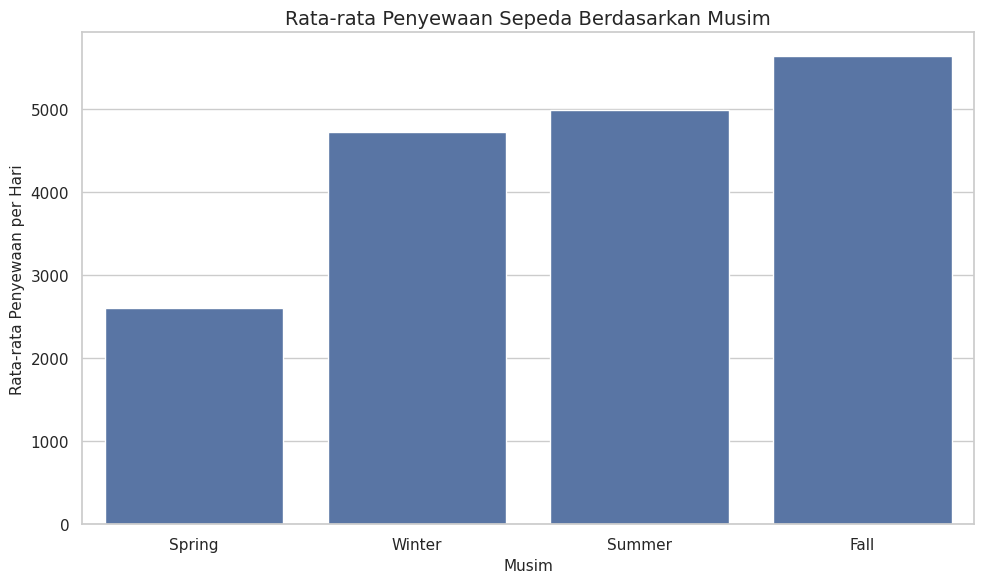

Musim dengan rata-rata penyewaan tertinggi:


,2
season,3
average_rentals,5644.303191
total_rentals,1061129
number_of_days,188
season_name,Fall


Musim dengan rata-rata penyewaan terendah:


,0
season,1
average_rentals,2604.132597
total_rentals,471348
number_of_days,181
season_name,Spring


In [28]:
season_plot = season_summary.sort_values("average_rentals")

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=season_plot,
    x="season_name",
    y="average_rentals"
)

plt.title("Rata-rata Penyewaan Sepeda Berdasarkan Musim")
plt.xlabel("Musim")
plt.ylabel("Rata-rata Penyewaan per Hari")
plt.tight_layout()
plt.show()

print("Musim dengan rata-rata penyewaan tertinggi:")
display(
    season_summary.loc[
        season_summary["average_rentals"].idxmax()
    ]
)

print("Musim dengan rata-rata penyewaan terendah:")
display(
    season_summary.loc[
        season_summary["average_rentals"].idxmin()
    ]
)

### Pertanyaan 2: Pada jam berapa rata-rata penyewaan sepeda mencapai nilai tertinggi pada hari kerja dan hari libur selama periode 2011–2012?

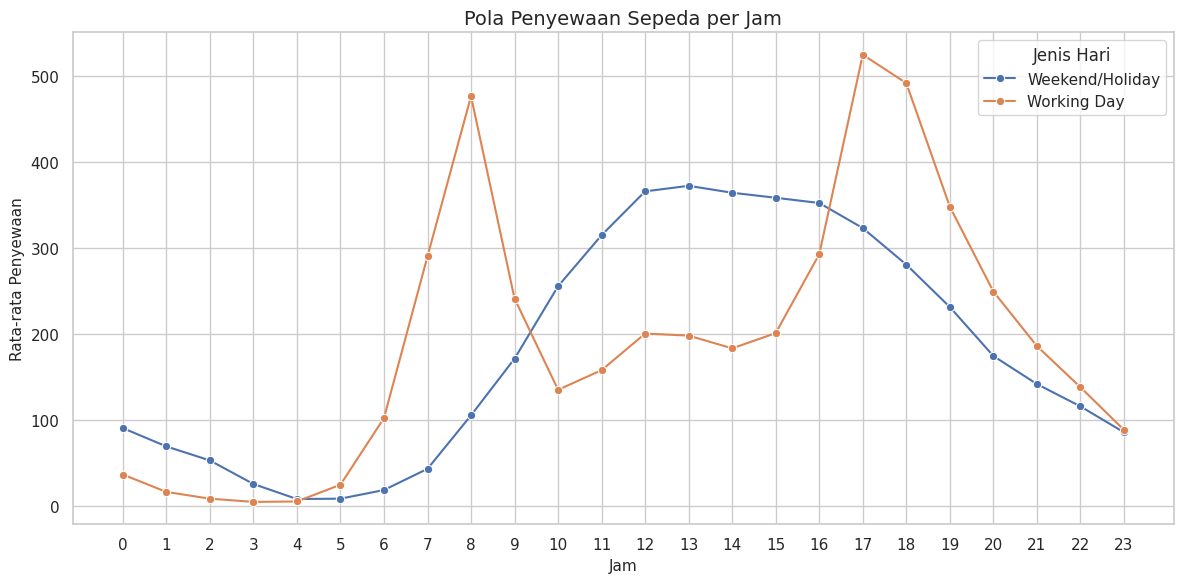

Tiga jam dengan rata-rata penyewaan tertinggi untuk setiap jenis hari:


,workingday,hr,average_rentals,total_rentals,observations,day_type
13,0,13,372.731602,86101,231,Weekend/Holiday
12,0,12,366.259740,84606,231,Weekend/Holiday
14,0,14,364.645022,84233,231,Weekend/Holiday
41,1,17,525.290581,262120,499,Working Day
42,1,18,492.226908,245129,498,Working Day
32,1,8,477.006048,236595,496,Working Day


In [29]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=hour_summary,
    x="hr",
    y="average_rentals",
    hue="day_type",
    marker="o"
)

plt.title("Pola Penyewaan Sepeda per Jam")
plt.xlabel("Jam")
plt.ylabel("Rata-rata Penyewaan")
plt.xticks(range(0, 24))
plt.legend(title="Jenis Hari")
plt.tight_layout()
plt.show()

# Menampilkan tiga jam dengan rata-rata penyewaan tertinggi
top_hours = (
    hour_summary.sort_values(
        ["workingday", "average_rentals"],
        ascending=[True, False]
    )
    .groupby("day_type")
    .head(3)
    .sort_values(["day_type", "average_rentals"], ascending=[True, False])
)

print("Tiga jam dengan rata-rata penyewaan tertinggi untuk setiap jenis hari:")
display(top_hours)

**Insight:** (Opsional)
- Visualisasi pertama membandingkan rata-rata penyewaan harian pada empat musim sehingga periode dengan permintaan relatif tinggi dan rendah dapat diidentifikasi.
- Visualisasi kedua memperlihatkan perubahan rata-rata penyewaan dari pukul 00.00 hingga 23.00 serta perbedaan pola antara hari kerja dan akhir pekan atau hari libur.
- Nilai puncak dan perbedaan antarkelompok ditentukan berdasarkan hasil tabel dan grafik yang dihasilkan.

## Analisis Lanjutan (Opsional)

Pengelompokan tingkat permintaan:


,demand_level,number_of_days,average_rentals,minimum_rentals,maximum_rentals
0,Low,244,2312.065574,22,3740
1,Medium,244,4522.225410,3744,5312
2,High,243,6687.703704,5315,8714


Persentase tingkat permintaan berdasarkan musim:


demand_level,Low,Medium,High
season,,,
Fall,6.91,42.02,51.06
Spring,77.35,18.23,4.42
Summer,20.11,38.59,41.30
Winter,30.34,34.27,35.39


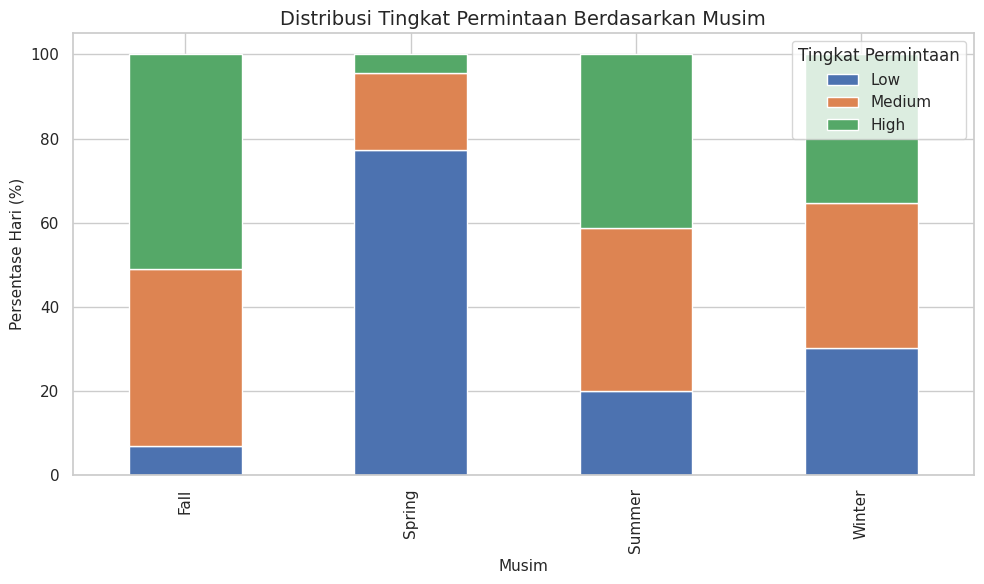

In [30]:
# Mengelompokkan tingkat permintaan berdasarkan kuartil
day_clean["demand_level"] = pd.qcut(
    day_clean["cnt"],
    q=3,
    labels=["Low", "Medium", "High"],
    duplicates="drop"
)

# Ringkasan tingkat permintaan
demand_summary = (
    day_clean.groupby("demand_level", observed=True)
    .agg(
        number_of_days=("cnt", "count"),
        average_rentals=("cnt", "mean"),
        minimum_rentals=("cnt", "min"),
        maximum_rentals=("cnt", "max")
    )
    .reset_index()
)

print("Pengelompokan tingkat permintaan:")
display(demand_summary)

# Membandingkan tingkat permintaan berdasarkan musim
demand_by_season = pd.crosstab(
    day_clean["season"].map(season_labels),
    day_clean["demand_level"],
    normalize="index"
) * 100

print("Persentase tingkat permintaan berdasarkan musim:")
display(demand_by_season.round(2))

demand_by_season.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Distribusi Tingkat Permintaan Berdasarkan Musim")
plt.xlabel("Musim")
plt.ylabel("Persentase Hari (%)")
plt.legend(title="Tingkat Permintaan")
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Binning membagi hari menjadi kelompok permintaan rendah, sedang, dan tinggi berdasarkan distribusi jumlah penyewaan.
- Perbandingan distribusi tingkat permintaan berdasarkan musim membantu mengidentifikasi musim yang lebih sering mengalami permintaan tinggi. Batas kategori berasal dari kuartil dataset, bukan standar operasional yang telah ditetapkan perusahaan.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Rata-rata jumlah penyewaan sepeda berbeda antar musim. Berdasarkan hasil analisis awal dataset, musim Fall memiliki rata-rata sekitar 5.644 penyewaan per hari, sedangkan Spring sekitar 2.604 penyewaan per hari. Dengan demikian, Fall dapat menjadi prioritas dalam perencanaan ketersediaan sepeda, sementara kebutuhan pada Spring perlu disesuaikan dengan tingkat permintaannya. Hasil akhir tetap perlu dicocokkan dengan output notebook setelah cleaning.

- **Conclusion pertanyaan 2:** Pola penyewaan sepeda berubah sepanjang hari dan dapat berbeda antara hari kerja dan akhir pekan atau hari libur. Jam dengan rata-rata penyewaan tertinggi untuk setiap jenis hari ditentukan melalui tabel dan visualisasi EDA. Informasi ini dapat digunakan untuk menyesuaikan jadwal pemeriksaan, redistribusi, dan ketersediaan sepeda pada jam-jam dengan permintaan tinggi.

- **Conclusion analisis lanjutan:** Pengelompokan binning membantu membedakan hari dengan permintaan rendah, sedang, dan tinggi berdasarkan distribusi penyewaan. Hasilnya dapat menjadi dasar awal untuk mengatur kapasitas operasional berdasarkan tingkat permintaan.

**Rekomendasi Action Item:**
- **Prioritaskan ketersediaan sepeda pada periode dengan permintaan tinggi.** Gunakan perbandingan rata-rata penyewaan per musim untuk membantu merencanakan kapasitas sepeda dan jadwal pemeliharaan.
- **Sesuaikan operasional berdasarkan jam permintaan.** Gunakan pola penyewaan per jam untuk menentukan waktu yang tepat bagi pemeriksaan, redistribusi, dan penyiapan sepeda, dengan mempertimbangkan perbedaan hari kerja dan akhir pekan atau hari libur.
- **Terapkan pemantauan permintaan secara berkala.** Perbarui ringkasan penyewaan berdasarkan tanggal, musim, dan jenis hari agar keputusan operasional mengikuti pola penggunaan aktual.
- **Evaluasi rekomendasi menggunakan data terbaru.** Bandingkan rata-rata penyewaan sebelum dan sesudah penyesuaian operasional untuk menilai apakah ketersediaan sepeda telah sesuai dengan kebutuhan pengguna.